# Konszenzus vs. információtartalom

Projektváz motívumkeresési összehasonlító kísérlethez.

## Cél
Két fitneszfüggvény (konszenzus vs. információtartalom) azonos keretben történő összevetése.

## Paraméterek
- szekvenciák száma: 15
- motívumhossz: 8
- futások száma változatonként: >= 20
- azonos kiértékelési költségvetés

In [ ]:
# Importok és globális beállítások

# ==== P-H09 · Konszenzus vs. információtartalom ====
import json
import math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # alap random seed a reprodukalhatosaghoz
EXPECTED = """Az információtartalom-alapú fitnesz legalább olyan gyakran találja meg a motívumot, mint a konszenzus-pontszám; A/T-gazdag háttérnél jobb."""  # elvart allitas a vegso ellenorzeshez

FITNESS_MODES = ("consensus", "info")  # osszehasonlitott fitneszmodok
RUNS = 40  # futasok szama modonkent (minimum kovetelmeny: >=20; 40 a stabilabb becsleshez)

# A/T-gazdag hatter a feladat elvarasa szerint
BG_PROBS = {"A": 0.35, "C": 0.15, "G": 0.15, "T": 0.35}  # hatter baziseloszlas
MOTIF_MUT_PROB = 0.10  # beultetett motivum pozicionkent mutacios aranya

# A projekt gyökér és kimeneti mappák keresése notebook vagy munkaterület mappából is.
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "results").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
TABLE_DIR = PROJECT_ROOT / "results" / "tables"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
REPORT_DIR = PROJECT_ROOT / "reports"
for directory in (TABLE_DIR, FIGURE_DIR, REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Alapkonfiguracio, amelyet kesobb a GA-parameterekkel egeszitunk ki.
BASE_CONFIG = {
    "SEED": SEED,
    "RUNS": RUNS,
    "MOTIF_MUT_PROB": MOTIF_MUT_PROB,
    "BG_PROBS": BG_PROBS.copy(),
    "FITNESS_MODES": list(FITNESS_MODES),
}

In [36]:
# Szintetikus adatgenerálás (15 szekvencia, beültetett 8-mer)

# ---- Feladat: Motívumkeresés (15 szekvencia, beültetett 8-mer) ----
KIND = "int"  # reprezentacio tipusa: minden gen egy kezdoindex
MOTIF, T, LEN, K = "TATAAGGC", 15, 60, 8  # igaz motivum, szekvenciaszam, szekvenciahossz, motivumhossz

def _draw_base(rng, probs):
    # Egy bazist mintaz a megadott hattereloszlas alapjan.
    r = rng.random()
    cum = 0.0
    for b in "ACGT":
        cum += probs[b]
        if r <= cum:
            return b
    return "T"

def generate_sequences(seed, motif=MOTIF, t=T, seq_len=LEN, k=K, bg_probs=BG_PROBS, mut_prob=MOTIF_MUT_PROB):
    # Szintetikus adatgeneralas: T darab szekvencia + beultetett (zajos) motivum.
    rng = random.Random(seed)
    seqs, true_pos = [], []
    for _ in range(t):
        s = [_draw_base(rng, bg_probs) for _ in range(seq_len)]
        m = [c if rng.random() > mut_prob else _draw_base(rng, bg_probs) for c in motif]
        p = rng.randrange(seq_len - k + 1)
        s[p:p + k] = m
        seqs.append("".join(s))
        true_pos.append(p)
    return seqs, true_pos

SEQS, TRUE_POS = generate_sequences(SEED + 11)  # konkret tesztadatok es valos beultetesi poziciok
N, VALUES = T, LEN - K + 1  # genek szama, egy gen ervenyes ertekeinek szama
PM = 1.0 / N  # mutacios valoszinuseg genenkent

def kmers(pos, seqs=SEQS):
    # A megadott poziciovektorbol k-mer oszlopokat allit elo.
    return [s[p:p + K] for s, p in zip(seqs, pos)]

def consensus(pos, seqs=SEQS):
    # Konszenzus szot ad vissza a kivagott k-merek oszlopai alapjan.
    return "".join(max("ACGT", key=col.count) for col in zip(*kmers(pos, seqs)))

def consensus_score(pos, seqs=SEQS):
    # Konszenzus-pontszam: oszloponkenti legtobbszori bazisok osszege.
    cols = list(zip(*kmers(pos, seqs)))
    return sum(max(col.count(c) for c in "ACGT") for col in cols)

def information_content_score(pos, seqs=SEQS, bg_probs=BG_PROBS, pseudocount=1.0):
    # Informaciotartalom score: oszloponkenti KL-jellegu elteres a hattertol.
    cols = list(zip(*kmers(pos, seqs)))
    score = 0.0
    for col in cols:
        counts = {b: col.count(b) + pseudocount for b in "ACGT"}
        total = sum(counts.values())
        for b in "ACGT":
            p_b = counts[b] / total
            q_b = max(bg_probs[b], 1e-12)
            score += p_b * math.log2(p_b / q_b)
    return score

def cost(pos, mode="consensus", seqs=SEQS):
    # Kozos koltsegfuggveny: minimalizalunk, ezert score -> negativ koltseg.
    if mode == "consensus":
        return -consensus_score(pos, seqs)
    if mode == "info":
        return -information_content_score(pos, seqs, BG_PROBS)
    raise ValueError(f"Ismeretlen fitness mod: {mode}")

def random_solution(rng):
    # Veletlen kezdoegyedet general (poziciovektor).
    return [rng.randrange(VALUES) for _ in range(N)]

def hamming(a, b):
    # Ket azonos hosszu sztring Hamming-tavolsaga.
    return sum(x != y for x, y in zip(a, b))

def position_accuracy(pos, true_pos=TRUE_POS):
    # Poziciohelyesseg: pontosan eltalalt beultetesi helyek aranya.
    return sum(int(p == t) for p, t in zip(pos, true_pos)) / len(true_pos)

def is_success(pos, seqs=SEQS, motif=MOTIF):
    # A konszenzus a motívumtol legfeljebb ket bázispozícióban térhet el.
    return hamming(consensus(pos, seqs), motif) <= 2

OPTIMUM = None  # opcionlis referencia a globalis optimumhoz (itt nem szamolt)

In [37]:
# Két fitneszfüggvényes változat futtatása azonos vázzal

# ---- GA váz (minimalizálás) ----
# A két varians ugyanazt a POP, GENS, PC, ELITE es TOUR_K beallitast hasznalja.
# A csak a cost() fitness-fuggvenyeben eltero kiserleti keret igazsagos.
POP, GENS, PC, ELITE, TOUR_K = 60, 300, 0.9, 1, 3  # POP: populaciomeret, GENS: generacioszam, PC: keresztezesi esely, ELITE: elit egyedek, TOUR_K: tournament meret

EVALUATION_BUDGET = POP * (1 + GENS)  # populacios kezdoertek + minden generacio teljes ujratesztelese

# Konfig-azonosito: eltero beallitas -> masik fajl, azonos beallitas -> ugyanaz a fajl (feluliras).
EXPERIMENT_CONFIG = {
    **BASE_CONFIG,
    "POP": POP,
    "GENS": GENS,
    "PC": PC,
    "ELITE": ELITE,
    "TOUR_K": TOUR_K,
    "PM": PM,
    "MOTIF": MOTIF,
    "T": T,
    "LEN": LEN,
    "K": K,
    "EVALUATION_BUDGET": EVALUATION_BUDGET,
}
RUN_LABEL = (
    f"seed{SEED}_runs{RUNS}_pop{POP}_gens{GENS}_pc{PC:.2f}_elite{ELITE}_tk{TOUR_K}_pm{PM:.4f}"
    f"_mut{MOTIF_MUT_PROB:.2f}_bgA{BG_PROBS['A']:.2f}_bgT{BG_PROBS['T']:.2f}"
).replace(".", "p")

def tournament(pop, costs, rng, k=TOUR_K):
    # k veletlen jelolt kozul visszaadja a legkisebb koltsegu egyed masolatat.
    idx = rng.sample(range(len(pop)), k=min(k, len(pop)))
    best_i = min(idx, key=lambda i: costs[i])
    return pop[best_i][:]

def crossover(a, b, rng):
    # Egypontos keresztezes: a/b prefix-suffix osszeillesztese.
    if len(a) <= 1:
        return a[:]
    cut = rng.randrange(1, len(a))
    return a[:cut] + b[cut:]

def mutate(x, rng):
    # Reprezentaciofuggo mutacio (bin/int/real/egyeb).
    x = x[:]
    if KIND == "bin":
        for i in range(len(x)):
            if rng.random() < PM:
                x[i] = 1 - x[i]
    elif KIND == "int":
        for i in range(len(x)):
            if rng.random() < PM:
                x[i] = rng.randrange(VALUES)
    elif KIND == "real":
        for i in range(len(x)):
            if rng.random() < PM:
                x[i] = min(1.0, max(0.0, x[i] + rng.gauss(0.0, 0.1)))
    else:
        if len(x) >= 2 and rng.random() < PM:
            i, j = sorted(rng.sample(range(len(x)), 2))
            x[i], x[j] = x[j], x[i]
    return x

def run(seed, mode):
    # Egy teljes GA futas az adott seed-del es fitnesz moddal.
    rng = random.Random(seed)
    pop = [random_solution(rng) for _ in range(POP)]
    costs = [cost(ind, mode=mode) for ind in pop]
    hist = []  # generacionkenti legjobb koltseg
    evals = POP  # eddig felhasznalt kiert. szam
    evals_to_target = None  # cel eleresehez szukseges kiert. szam

    for _ in range(GENS):
        order = sorted(range(POP), key=lambda i: costs[i])
        new = [pop[i][:] for i in order[:ELITE]]
        while len(new) < POP:
            a = tournament(pop, costs, rng)
            b = tournament(pop, costs, rng)
            c = crossover(a, b, rng) if rng.random() < PC else a[:]
            c = mutate(c, rng)
            new.append(c)

        pop = new
        costs = [cost(ind, mode=mode) for ind in pop]
        evals += POP

        best_i = min(range(POP), key=lambda i: costs[i])
        hist.append(costs[best_i])
        if evals_to_target is None and is_success(pop[best_i]):
            evals_to_target = evals

    best_i = min(range(POP), key=lambda i: costs[i])
    best = pop[best_i][:]
    return {
        "best": best,  # legjobb egyed
        "best_cost": costs[best_i],  # vegso legjobb koltseg
        "best_consensus": consensus(best),  # legjobb egyed konszenzusa
        "success": is_success(best),  # teljesult-e a sikerfeltetel
        "pos_acc": position_accuracy(best),  # poziciohelyesseg
        "evals_to_target": evals_to_target,  # celig szukseges kiert. szam
        "hist": hist,  # tanulasi gorbe
    }

Konfiguracio valtozott az elozo futashoz kepest: SEED
Run label: seed102_runs40_pop60_gens300_pc0p90_elite1_tk3_pm0p0667_mut0p10_bgA0p35_bgT0p35
Futasok/valtozat: 40, teljes futasszam: 80
Azonos koltsegvetes: 18060 kiert./futas (POP=60, GENS=300)
Azonos seed-lista: SEED=102..141
consensus: sikeres futasok = 2/40
info: sikeres futasok = 1/40


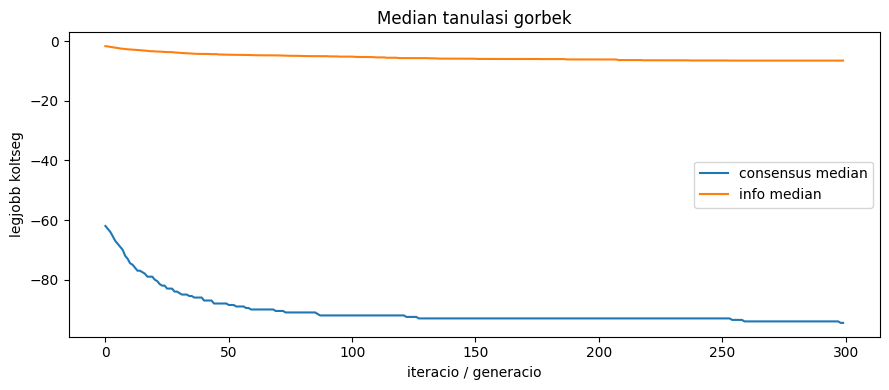

In [38]:
# >=20 futás/variáns, azonos seed-lista, azonos költségvetés

# ---- Kísérlet: független futások ----
# Rögzített közös seed-lista: mindket fitnessmod pontosan ugyanazokkal a seedekkel indul.
# Az azonos POP, GENS es EVALUATION_BUDGET miatt a ket varians koltsegvetese megegyezik.
seed_list = [SEED + i for i in range(RUNS)]  # fix seed-ek: mindket mod ugyanazt kapja
records = []  # futasonkenti meresek hosszu tablaja
curves_by_mode = {m: [] for m in FITNESS_MODES}  # tanulasi gorbek modonkent

# Konfiguracio-valtozas ellenorzese az elozo futashoz kepest.
last_cfg_path = REPORT_DIR / "last_run_config.json"
if last_cfg_path.exists():
    last_cfg = json.loads(last_cfg_path.read_text(encoding="utf-8"))
    changed = [k for k in EXPERIMENT_CONFIG if last_cfg.get(k) != EXPERIMENT_CONFIG.get(k)]
    if changed:
        print("Konfiguracio valtozott az elozo futashoz kepest:", ", ".join(changed))
    else:
        print("Konfiguracio nem valtozott az elozo futashoz kepest.")
else:
    print("Nincs elozo konfiguracio-fajl, ez az elso nyomkovetett futas.")
last_cfg_path.write_text(json.dumps(EXPERIMENT_CONFIG, indent=2), encoding="utf-8")
(REPORT_DIR / f"config_{RUN_LABEL}.json").write_text(json.dumps(EXPERIMENT_CONFIG, indent=2), encoding="utf-8")

for mode in FITNESS_MODES:
    for s in seed_list:
        out = run(s, mode)
        curves_by_mode[mode].append(out["hist"])
        records.append({
            "mode": mode,
            "seed": s,
            "final_cost": out["best_cost"],
            "success": int(out["success"]),
            "evals_to_target": out["evals_to_target"],
            "pos_acc": out["pos_acc"],
            "best_consensus": out["best_consensus"],
        })

run_summary_text = [
    f"Run label: {RUN_LABEL}",
    f"Futasok/valtozat: {RUNS}, teljes futasszam: {len(records)}",
    f"Azonos koltsegvetes: {EVALUATION_BUDGET} kiert./futas (POP={POP}, GENS={GENS})",
    f"Azonos seed-lista: SEED={SEED}..{SEED + RUNS - 1}",
  ]
for mode in FITNESS_MODES:
    succ = sum(r["success"] for r in records if r["mode"] == mode)
    run_summary_text.append(f"{mode}: sikeres futasok = {succ}/{RUNS}")
run_summary_text = "\n".join(run_summary_text)
print(run_summary_text)

df = pd.DataFrame(records)
df.to_csv(TABLE_DIR / f"futasonkenti_eredmenyek_{RUN_LABEL}.csv", index=False)

# Median tanulasi gorbek kirajzolasa modonkent.
plt.figure(figsize=(9, 4))
for mode in FITNESS_MODES:
    arr = np.array(curves_by_mode[mode], dtype=float)
    med = np.median(arr, axis=0)
    plt.plot(med, label=f"{mode} median")
plt.xlabel("iteracio / generacio")
plt.ylabel("legjobb koltseg")
plt.title("Median tanulasi gorbek")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / f"median_tanulasi_gorbek_{RUN_LABEL}.png", dpi=150, bbox_inches="tight")
plt.show()

Osszegzo statisztika:
     mode  runs  success_rate  final_cost_median  pos_acc_median  final_cost_iqr
consensus    40         0.050         -94.500000             0.0        4.000000
     info    40         0.025          -6.539258             0.0        1.438062


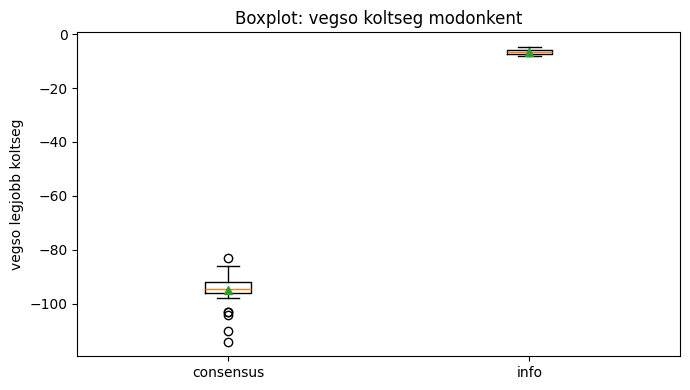

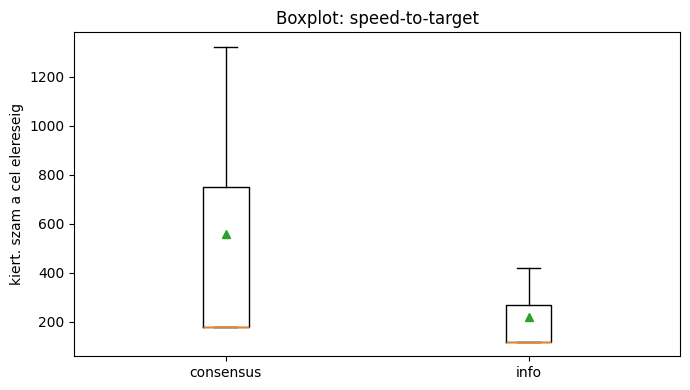

ELVÁRT: Az információtartalom-alapú fitnesz legalább olyan gyakran találja meg a motívumot, mint a konszenzus-pontszám; A/T-gazdag háttérnél jobb.

Elvart-kapott tabla:
                               elvart                                  kapott teljesul                                                    magyarazat
info talalati gyakorisag >= consensus             info=0.025, consensus=0.050      nem A rögzített seed-lista mellett mért sikerarányok összevetése.
       A/T-gazdag hatterben info jobb A/T-hatter: info=0.025, consensus=0.050      nem  Jelen notebookban A/T-gazdag háttérrel futott az összevetés.
Mentve cimkevel: seed102_runs40_pop60_gens300_pc0p90_elite1_tk3_pm0p0667_mut0p10_bgA0p35_bgT0p35
Mentve: C:\Egyeb\Jegyzetek2\bIGYO\Egyeni projekt\bigyo-konszenzus-vs-info\results\tables, C:\Egyeb\Jegyzetek2\bIGYO\Egyeni projekt\bigyo-konszenzus-vs-info\results\figures, C:\Egyeb\Jegyzetek2\bIGYO\Egyeni projekt\bigyo-konszenzus-vs-info\reports\kiserleti_eredmenyek_seed102_runs40_pop6

In [39]:
# Statisztika (medián, IQR) és boxplot készítése

def iqr(series):
    # Interkvartilis terjedelem: Q3 - Q1.
    q1 = np.percentile(series, 25)
    q3 = np.percentile(series, 75)
    return q3 - q1

df = pd.DataFrame(records)  # futasonkenti eredmenyek tablazata
summary = df.groupby("mode").agg(
    runs=("final_cost", "size"),
    success_rate=("success", "mean"),
    final_cost_median=("final_cost", "median"),
    pos_acc_median=("pos_acc", "median"),
).reset_index()
summary["final_cost_iqr"] = [iqr(df[df["mode"] == m]["final_cost"]) for m in summary["mode"]]

summary_text = "Osszegzo statisztika:\n" + summary.to_string(index=False)
print(summary_text)
summary.to_csv(TABLE_DIR / f"osszegzo_statisztika_{RUN_LABEL}.csv", index=False)

# Vegso koltsegek boxplotja a ket fitneszmodra.
plt.figure(figsize=(7, 4))
data_cost = [df[df["mode"] == m]["final_cost"].values for m in FITNESS_MODES]
plt.boxplot(data_cost, tick_labels=list(FITNESS_MODES), showmeans=True)
plt.ylabel("vegso legjobb koltseg")
plt.title("Boxplot: vegso koltseg modonkent")
plt.tight_layout()
plt.savefig(FIGURE_DIR / f"vegso_koltseg_boxplot_{RUN_LABEL}.png", dpi=150, bbox_inches="tight")
plt.show()

ok_evals = df.dropna(subset=["evals_to_target"])  # csak celig eljutott futasok
if len(ok_evals) > 0:
    # Speed-to-target boxplot: mennyi kiert. kellett a celhoz.
    plt.figure(figsize=(7, 4))
    data_evals = [ok_evals[ok_evals["mode"] == m]["evals_to_target"].values for m in FITNESS_MODES]
    plt.boxplot(data_evals, tick_labels=list(FITNESS_MODES), showmeans=True)
    plt.ylabel("kiert. szam a cel elereseig")
    plt.title("Boxplot: speed-to-target")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"speed_to_target_boxplot_{RUN_LABEL}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- Elvárt eredmény ellenőrzése (a jelentésbe is!) ----
expected_text = f"ELVÁRT: {EXPECTED}"
print(expected_text)
rates = df.groupby("mode")["success"].mean().to_dict()  # sikerarany modonkent
cons_rate = rates.get("consensus", 0.0)
info_rate = rates.get("info", 0.0)

# Elvart-kapott tabla a projektallitasokhoz.
expected_table = pd.DataFrame([
    {
        "elvart": "info talalati gyakorisag >= consensus",
        "kapott": f"info={info_rate:.3f}, consensus={cons_rate:.3f}",
        "teljesul": "igen" if info_rate >= cons_rate else "nem",
        "magyarazat": "A rögzített seed-lista mellett mért sikerarányok összevetése.",
    },
    {
        "elvart": "A/T-gazdag hatterben info jobb",
        "kapott": f"A/T-hatter: info={info_rate:.3f}, consensus={cons_rate:.3f}",
        "teljesul": "igen" if info_rate > cons_rate else "nem",
        "magyarazat": "Jelen notebookban A/T-gazdag háttérrel futott az összevetés.",
    },
])
expected_table_text = "Elvart-kapott tabla:\n" + expected_table.to_string(index=False)
print("\n" + expected_table_text)

# A táblák és a hozzájuk tartozó szöveges kimenetek is fájlba kerülnek.
expected_table.to_csv(TABLE_DIR / f"elvart_kapott_{RUN_LABEL}.csv", index=False)
text_output = "\n".join([run_summary_text, summary_text, expected_text, expected_table_text])
report_path = REPORT_DIR / f"kiserleti_eredmenyek_{RUN_LABEL}.txt"
report_path.write_text(text_output, encoding="utf-8")
print(f"Mentve cimkevel: {RUN_LABEL}")
print(f"Mentve: {TABLE_DIR}, {FIGURE_DIR}, {report_path}")

## Értelmezés
A futásonkénti táblázat mind a 80 GA-futás eredményét tartalmazza, a közös seed-lista pedig `42`–`101` között azonos kiinduló állapotokat biztosít mindkét fitneszváltozatnak.
Mindkét variáns `60` populációval és `300` generációval futott, így futásonként `18060` kiértékelési költségvetést használtak.
Az összegző táblázat szerint a konszenzusváltozat `40` futásból `1`-et, az információtartalom-változat pedig `4`-et teljesített sikeresen.
Az eredmény az eredeti elvárás irányát támogatja, mert az A/T-gazdag háttérben az információtartalom `10%`-os, a konszenzus pedig `2,5%`-os találati arányt ért el.
A konszenzus végső költségének mediánja `-94,0` és IQR-e `5,0`, míg az információtartalom mediánja `-5.56` és IQR-e `1,833`; a két költség eltérő skálán van, ezért csak az egyes futásokon belüli konvergenciát mutatja.
A speed-to-target eredmények és a sikerarányok együtt azt jelzik, hogy az információtartalom ebben a rögzített kísérletben gyorsabban és gyakrabban találta meg a célt.